# Step 0 · Sector definition and extraction: underwater drones

This notebook builds the **underwater drones** sector from PATSTAT (Tutorial 0, Notebook 1: keywords and
classification codes combined) and validates it (PW kick-off: hand-label about 100 random families).

| Section | What it does |
|---|---|
| 1 | Setup: environment, configuration, labels, helper functions |
| 2 | Candidate pool: one SQL pass that collects every family that *could* belong to the sector |
| 3 | Application- and family-level data: applications, family year, titles, abstracts, CPC and IPC codes |
| 4 | The sector: five selection blocks, grey-zone exclusion rules, hand-labelled corrections |
| 5 | Block overlap |
| 6 | Labelling protocol and samples to label |
| 7 | Validation: precision, agreement, grey zones, recall, false positives, corrections |
| 8 | Lexical vs semantic retrieval (keywords, BM25, TF-IDF, Patent SBERT) and UMAP maps |
| 9 | Saved outputs (used by `02_clean`) |
| 10 | Summary: the numbers to report and the checks still open |

**Why two steps (SQL, then Python)?** SQL `LIKE` cannot match whole words, so `'%rov%'` would also catch
*improve* and *provide*. SQL therefore only collects a broad candidate pool (CPC codes and keyword phrases);
the exact rules, including whole-word acronyms, are applied in Python with regular expressions (`pw_utils`).

**Counting rules** (Tutorial 0, Notebook 2): one row per DOCDB family; family year = earliest priority year of
the family (minimum `earliest_filing_year` over its applications), 2000–2025; patents of invention only;
dummy applications excluded (Tutorial 1); years after `LAST_COMPLETE_YEAR` flagged as truncated, never read as
a decline. Language is **not** a filter for the sector: it only matters for the text methods (Section 8).

## 1 · Setup

To count **utility models** with the same query (robustness check, IM_Theory_0), uncomment the first line:
everything is then written to `outputs/<env>/step0_UM/` and the PI outputs are untouched.

In [1]:
# %env PW_IPR_TYPE=UM
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS209_APPLN_IPC,
    TLS224_APPLN_CPC,
)

sys.path.append(str(Path.cwd()))
import config as C
from pw_utils import (BLOCKS, EXCLUSIONS, apply_blocks, compile_any, fetch_by_ids, flags_by_family, grey_zone_flags,
                      precision_table, regex_to_like_phrases, summarise_blocks, wilson)

C.OUT_STEP0.mkdir(parents=True, exist_ok=True)
(C.OUT_STEP0 / "raw").mkdir(exist_ok=True)

patstat = PatstatClient(env=C.ENV)
db = patstat.orm()

print(f"Sector: {C.SECTOR_NAME} | env: {C.ENV} | years {C.YEAR_MIN}-{C.YEAR_MAX} "
      f"| last complete year {C.LAST_COMPLETE_YEAR} | IPR type {C.IPR_TYPE}")

Sector: Underwater drones | env: PROD | years 2000-2025 | last complete year 2022 | IPR type PI


In [2]:
# ---------------------------------------------------------------- helpers

def fetch_by_family(make_query, family_ids):
    """Chunked IN (...) queries (see pw_utils.fetch_by_ids)."""
    return fetch_by_ids(patstat, make_query, family_ids)


def stripped(col):
    """Classification symbol without blanks: 'B63G   8/00' -> 'B63G8/00' (PATSTAT pads symbols, Tutorial 0)."""
    return func.replace(col, " ", "")


def sql_prefix_any(col, prefixes):
    s = stripped(col)
    return or_(*(s.like(p.replace(" ", "") + "%") for p in prefixes))


def sql_like_any(col, phrases):
    low = func.lower(col)
    return or_(*(low.like(f"%{p}%") for p in phrases))

**Labels.** Every `.csv` in `labels/` is read (see `labels/README.md`): one row per family, `is_relevant` = 0/1
(strict rule, used for the sector and every validation number), `is_relevant_broad` = 0/1 (broad rule, used only as
an upper bound in 7.1 and 7.3; if missing it is set equal to `is_relevant`), `sample` = where the family comes from (`sector`, `candidates`, `block5`, `broad_net`, `broad_net_outside`,
`discovery`, `other`), `grey_zone` and `note` (the reason for the label). Labels are read **before** the queries, because the families
labelled relevant must be downloaded even when the query misses them (Section 4, corrections).

In [3]:
def load_labels():
    """All label files in labels/ (utf-8-sig: files saved by Excel start with a BOM); one row per family."""
    frames = []
    for f in sorted(C.LABEL_DIR.glob("*.csv")):
        d = pd.read_csv(f, encoding="utf-8-sig")
        if C.LABEL_COL not in d.columns or "docdb_family_id" not in d.columns:
            print(f"skipped {f.name}: needs docdb_family_id and {C.LABEL_COL}")
            continue
        d = d[pd.to_numeric(d[C.LABEL_COL], errors="coerce").isin([0, 1])].copy()
        d[C.LABEL_COL] = d[C.LABEL_COL].astype(int)
        broad = pd.to_numeric(d[C.LABEL_COL_BROAD], errors="coerce") if C.LABEL_COL_BROAD in d else pd.Series(np.nan, d.index)
        # the broad rule includes everything the strict rule includes
        d[C.LABEL_COL_BROAD] = np.maximum(broad.fillna(d[C.LABEL_COL]), d[C.LABEL_COL]).astype(int)
        d["docdb_family_id"] = d["docdb_family_id"].astype("int64")
        d["label_file"] = f.name
        frames.append(d)
    cols = ["docdb_family_id", C.LABEL_COL, C.LABEL_COL_BROAD, "label_file", "sample", "grey_zone"]
    if not frames:
        return pd.DataFrame(columns=cols)
    out = pd.concat(frames, ignore_index=True).drop_duplicates("docdb_family_id", keep="last")
    for c in ["sample", "grey_zone"]:
        if c not in out:
            out[c] = ""
        out[c] = out[c].fillna("").astype(str).str.strip()
    return out.reset_index(drop=True)


labels = load_labels()
print(f"Labelled families in {C.LABEL_DIR}/: {len(labels):,}")
if not labels.empty:
    display(labels.groupby("sample").agg(families=("docdb_family_id", "size"), relevant_strict=(C.LABEL_COL, "sum"),
                                         relevant_broad=(C.LABEL_COL_BROAD, "sum")))

# used for the corrections of Section 4 (strict rule)
labelled_relevant = set(labels.loc[labels[C.LABEL_COL] == 1, "docdb_family_id"])
labelled_not_relevant = set(labels.loc[labels[C.LABEL_COL] == 0, "docdb_family_id"])

Labelled families in labels/: 608


,families,relevant_strict,relevant_broad
sample,,,
block5,3,2,3
broad_net,64,8,15
broad_net_outside,86,10,19
candidates,100,59,67
discovery,164,72,98
other,6,2,4
sector,185,160,173


## 2 · Candidate pool (SQL)

A family enters the pool if one of its PI applications carries a block-1 or block-4 CPC code, or if a title or
abstract contains one of the keyword phrases of blocks 2 and 3, or a title contains ROV, AUV or UUV (block 5).
The families labelled relevant are added too (they may lie outside the query). Dummy applications (`appln_id` 0
or above 900,000,000, Tutorial 1) are excluded from every query.

In [4]:
family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
kw_phrases = regex_to_like_phrases(C.SPECIFIC_KEYWORDS + C.GENERIC_KEYWORDS)


def real_pi(q):
    """Patents of invention, no dummy applications."""
    return q.filter(TLS201_APPLN.ipr_type == C.IPR_TYPE,
                    TLS201_APPLN.appln_id > 0, TLS201_APPLN.appln_id < C.INVALID_APPLN_ID)


pool_cpc = real_pi(db.query(family_id)
                   .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
                   .filter(sql_prefix_any(TLS224_APPLN_CPC.cpc_class_symbol, C.BLOCK1_CPC + C.BLOCK4_CPC)))
pool_title = real_pi(db.query(family_id)
                     .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                     .filter(sql_like_any(TLS202_APPLN_TITLE.appln_title, kw_phrases)))
pool_abstract = real_pi(db.query(family_id)
                        .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                        .filter(sql_like_any(TLS203_APPLN_ABSTR.appln_abstract, kw_phrases)))
title_low = func.lower(TLS202_APPLN_TITLE.appln_title)
pool_b5 = real_pi(db.query(family_id)
                  .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                  .filter(or_(*(title_low.like(p) for p in C.BLOCK5_SQL_PATTERNS))))

pool_ids = pd.DataFrame(patstat.df(pool_cpc.union(pool_title, pool_abstract, pool_b5)))
pool_ids = pool_ids["docdb_family_id"].dropna().astype("int64").drop_duplicates().tolist()
query_pool = set(pool_ids)
pool_ids = sorted(query_pool | labelled_relevant)
print(f"Candidate pool: {len(query_pool):,} families from the query + "
      f"{len(set(pool_ids) - query_pool):,} labelled relevant outside it | SQL phrases: {len(kw_phrases)}")

Candidate pool: 36,407 families from the query + 40 labelled relevant outside it | SQL phrases: 44


## 3 · Application- and family-level data

For every candidate family we download its PI applications and keep the families whose **family year** (earliest
priority of the family) falls in 2000–2025. Titles, abstracts and codes are kept per application and pooled per
family (the two matching levels of Section 4).

In [5]:
apps = fetch_by_family(
    lambda ids: real_pi(db.query(
        TLS201_APPLN.docdb_family_id, TLS201_APPLN.inpadoc_family_id, TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth, TLS201_APPLN.appln_kind, TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year, TLS201_APPLN.earliest_filing_year, TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.granted, TLS201_APPLN.docdb_family_size, TLS201_APPLN.nb_citing_docdb_fam,
    ).filter(TLS201_APPLN.docdb_family_id.in_(ids))),
    pool_ids,
)
valid_year = apps["earliest_filing_year"].where(apps["earliest_filing_year"] != C.MISSING_YEAR)
apps["family_year"] = valid_year.groupby(apps["docdb_family_id"]).transform("min")
apps = apps[apps["family_year"].between(C.YEAR_MIN, C.YEAR_MAX)].copy()
apps["family_year"] = apps["family_year"].astype(int)
family_ids = apps["docdb_family_id"].drop_duplicates().tolist()
print(f"Applications: {len(apps):,} | families with family year {C.YEAR_MIN}-{C.YEAR_MAX}: {len(family_ids):,}")

Applications: 39,404 | families with family year 2000-2025: 25,001


In [6]:
def by_family(model, *cols, extra=None):
    """Rows of `model` (joined on appln_id) for the PI applications of the candidate families."""
    def make(ids):
        q = real_pi(db.query(TLS201_APPLN.docdb_family_id, *cols)
                    .join(model, TLS201_APPLN.appln_id == model.appln_id)
                    .filter(TLS201_APPLN.docdb_family_id.in_(ids)))
        return q.filter(extra) if extra is not None else q
    return fetch_by_family(make, family_ids)


titles = by_family(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id, TLS202_APPLN_TITLE.appln_title,
                   TLS202_APPLN_TITLE.appln_title_lg)
abstracts = by_family(TLS203_APPLN_ABSTR, TLS203_APPLN_ABSTR.appln_id, TLS203_APPLN_ABSTR.appln_abstract,
                      TLS203_APPLN_ABSTR.appln_abstract_lg)
cpc = by_family(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id, TLS224_APPLN_CPC.cpc_class_symbol)
cpc["cpc"] = cpc["cpc_class_symbol"].str.replace(" ", "", regex=False)
ipc = by_family(TLS209_APPLN_IPC, TLS209_APPLN_IPC.appln_id, TLS209_APPLN_IPC.ipc_class_symbol)
if ipc.empty:
    ipc = pd.DataFrame(columns=["docdb_family_id", "appln_id", "ipc_class_symbol", "ipc"])
else:
    ipc["ipc"] = ipc["ipc_class_symbol"].str.replace(" ", "", regex=False)
print(f"Titles: {len(titles):,} | abstracts: {len(abstracts):,} | CPC rows: {len(cpc):,} | IPC rows: {len(ipc):,}")

Titles: 39,268 | abstracts: 36,715 | CPC rows: 228,726 | IPC rows: 131,867


In [7]:
def join_unique(s):
    vals = [str(v).strip() for v in s.dropna().unique() if str(v).strip()]
    return " || ".join(vals)


def code_lists(df, col, key):
    return df.groupby(key)[col].agg(lambda s: sorted(set(s)))


def as_list(v):
    return v if isinstance(v, list) else []


# ---- one row per application
app_units = apps[["docdb_family_id", "appln_id"]].copy()
app_units["titles"] = app_units["appln_id"].map(titles.set_index("appln_id")["appln_title"]).fillna("")
app_units["abstracts"] = app_units["appln_id"].map(abstracts.set_index("appln_id")["appln_abstract"]).fillna("")
app_units["cpc_codes"] = app_units["appln_id"].map(code_lists(cpc, "cpc", "appln_id")).apply(as_list)
app_units["ipc_codes"] = app_units["appln_id"].map(code_lists(ipc, "ipc", "appln_id")).apply(as_list)

# ---- one row per family (texts and codes pooled)
fam = (apps.groupby("docdb_family_id")
       .agg(family_year=("family_year", "first"), n_applications=("appln_id", "nunique"),
            docdb_family_size=("docdb_family_size", "max"))
       .reset_index())
first_app = apps.sort_values(["docdb_family_id", "appln_filing_date", "appln_id"]).drop_duplicates("docdb_family_id")
fam["first_office"] = fam["docdb_family_id"].map(first_app.set_index("docdb_family_id")["appln_auth"])
fam["titles"] = fam["docdb_family_id"].map(titles.groupby("docdb_family_id")["appln_title"].agg(join_unique)).fillna("")
fam["abstracts"] = fam["docdb_family_id"].map(abstracts.groupby("docdb_family_id")["appln_abstract"].agg(join_unique)).fillna("")
fam["cpc_codes"] = fam["docdb_family_id"].map(code_lists(cpc, "cpc", "docdb_family_id")).apply(as_list)
fam["ipc_codes"] = fam["docdb_family_id"].map(code_lists(ipc, "ipc", "docdb_family_id")).apply(as_list)

# one English title and abstract per family, for labelling and NLP (NOT a filter for the sector)
def lang(col):
    """Language codes as stored on TIP may carry blanks or capitals: normalise before comparing."""
    return col.fillna("").astype(str).str.strip().str.lower()


def first_text(df, text_col, english_only):
    ok = df[text_col].fillna("").astype(str).str.strip().ne("")
    if english_only:
        ok &= lang(df[text_col + "_lg"]) == "en"
    return df[ok].drop_duplicates("docdb_family_id").set_index("docdb_family_id")[text_col]


print("Title languages:", lang(titles["appln_title_lg"]).value_counts().head(5).to_dict())
print("Abstract languages:", lang(abstracts["appln_abstract_lg"]).value_counts().head(5).to_dict())
fam["abstract_en"] = fam["docdb_family_id"].map(first_text(abstracts, "appln_abstract", True))
# English title; if a family has none, its title in another language (one title per application in PATSTAT)
fam["title_en"] = (fam["docdb_family_id"].map(first_text(titles, "appln_title", True))
                   .fillna(fam["docdb_family_id"].map(first_text(titles, "appln_title", False))))
print(f"Families with a title: {fam['title_en'].notna().mean():.1%}")
fam["has_en_abstract"] = fam["abstract_en"].notna()
print(f"Units: {len(app_units):,} applications, {len(fam):,} families | with English abstract: {fam['has_en_abstract'].mean():.1%}")

Title languages: {'en': 35373, 'de': 1140, 'es': 543, 'fr': 455, 'pt': 376}
Abstract languages: {'en': 33425, 'de': 779, 'es': 598, 'fr': 492, 'ko': 436}
Families with a title: 100.0%
Units: 39,404 applications, 25,001 families | with English abstract: 96.8%


## 4 · The sector

**Selection blocks** (a family is selected if at least one fires):

| Block | Rule |
|---|---|
| 1 · CPC | `B63G2008/002, 004, 005, 007, 008` (unmanned underwater vessels) **and** an underwater term in title or abstract |
| 2 · Specific keywords | a specific keyword (e.g. *autonomous underwater*, *underwater glider*, *robotic fish*) in title or abstract |
| 3 · Generic keywords | *remotely operated vehicle*, *underwater robot*, ... in the **title**, or in the abstract with a `B63` or `B25J` code |
| 4 · Neighbouring codes | `B63G8/` or `B63C11/` **and** a robot term (*robot*, *drone*, *ROV*, *AUV*, *UUV*, ...) |
| 5 · Acronym in the title | *ROV*, *AUV* or *UUV* as a whole word in the title |

**Grey-zone exclusion rule** (`config.EXCLUSION_RULES`): a selected family is removed when its title is about an
**energy device or offshore structure** (turbines, generators, energy supply, wind farms, propellers...) **and**
the title has no vehicle term (robot, ROV, AUV, unmanned, vehicle, inspection, monitoring...). This applies the labelling rule of Section 6 to the whole sector: offshore-wind
inspection drones stay in, wind-farm structures where an ROV is only mentioned go out.

**Hand-labelled corrections** (`USE_LABEL_CORRECTIONS`): families labelled 0 leave the sector, families labelled 1
that the rules miss enter it. They fix the cases the rules cannot see; their number is reported in 7.6.

The rules are applied at two **matching levels**, both kept: *application* (code and words on the same
application) and *family* (texts and codes of all the family's applications pooled, Tutorial 1: it recovers
inventions whose English text sits on another member of the family). `MATCH_LEVEL` (default `family`) decides.
All regular expressions live in `config.py`; acronyms are whole words, so *rov* does not match *improve*.

In [8]:
FLAGS = BLOCKS + ["has_cpc"] + EXCLUSIONS
RX_SPECIFIC, RX_GENERIC = compile_any(C.SPECIFIC_KEYWORDS), compile_any(C.GENERIC_KEYWORDS)

fam_level = apply_blocks(fam)
app_level = flags_by_family(apply_blocks(app_units))
app_level = summarise_blocks(app_level.reindex(fam["docdb_family_id"], fill_value=False)).reset_index()

fam["in_sector_family"] = fam_level["in_sector"].values
fam["in_sector_application"] = fam["docdb_family_id"].map(app_level.set_index("docdb_family_id")["in_sector"]).fillna(False)
chosen = fam_level if C.MATCH_LEVEL == "family" else fam[["docdb_family_id"]].merge(app_level, on="docdb_family_id", how="left")
for col in FLAGS + ["matched", "excluded", "n_blocks", "block_combo"]:
    fam[col] = chosen[col].values
fam["in_sector_rules"] = chosen["in_sector"].values        # the sector given by the rules (what Section 7 validates)
fam = pd.concat([fam, grey_zone_flags(fam)], axis=1)
fam["is_truncated"] = fam["family_year"] > C.LAST_COMPLETE_YEAR

# hand-labelled corrections
fam["corr_removed"] = C.USE_LABEL_CORRECTIONS & fam["in_sector_rules"] & fam["docdb_family_id"].isin(labelled_not_relevant)
fam["corr_added"] = C.USE_LABEL_CORRECTIONS & ~fam["in_sector_rules"] & fam["docdb_family_id"].isin(labelled_relevant)
fam["in_sector"] = (fam["in_sector_rules"] & ~fam["corr_removed"]) | fam["corr_added"]
fam.loc[fam["corr_added"], "block_combo"] = "added by label"

sector = fam[fam["in_sector"]].copy()
rule_sector = fam[fam["in_sector_rules"]].copy()
sector_ids = set(sector["docdb_family_id"])
print(f"Families selected by the blocks ({C.MATCH_LEVEL} level): {fam['matched'].sum():,} (out of {len(fam):,} candidates)")
print(f"  removed by the grey-zone exclusion rules: {(fam['matched'] & fam['excluded']).sum():,}")
print(f"  = sector given by the rules: {len(rule_sector):,} | application level: {fam['in_sector_application'].sum():,} "
      f"| family level: {fam['in_sector_family'].sum():,}")
print(f"  hand-labelled corrections: -{fam['corr_removed'].sum():,} labelled not relevant, "
      f"+{fam['corr_added'].sum():,} labelled relevant outside the rules")
print(f"SECTOR: {len(sector):,} families | truncated (> {C.LAST_COMPLETE_YEAR}): {sector['is_truncated'].sum():,}")

Families selected by the blocks (family level): 12,046 (out of 25,001 candidates)
  removed by the grey-zone exclusion rules: 104
  = sector given by the rules: 11,942 | application level: 11,936 | family level: 11,942
  hand-labelled corrections: -33 labelled not relevant, +90 labelled relevant outside the rules
SECTOR: 11,999 families | truncated (> 2022): 4,198


### 4.1 Grey zones

Topic flags (`config.GREY_ZONE_PATTERNS`, plus offshore-wind CPC codes) count how many sector families touch each
grey zone; the families the exclusion rules removed are listed below, so the team can check them.

In [9]:
GZ = [c for c in fam.columns if c.startswith("gz_")]
display(pd.DataFrame({"sector families": sector[GZ].sum(), "share of sector (%)": sector[GZ].mean() * 100}).round(1))
excl = fam[fam["matched"] & fam["excluded"]]
print(f"\nFamilies removed by the exclusion rules: {len(excl)}")
display(excl[["docdb_family_id", "title_en"] + [c for c in EXCLUSIONS if excl[c].any()]])

,sector families,share of sector (%)
gz_offshore_wind,65,0.5
gz_hybrid_surface,524,4.4
gz_hybrid_air,676,5.6
gz_outside_sea,134,1.1



Families removed by the exclusion rules: 104


,docdb_family_id,title_en,ex_energy_device
703,33016126,Wind power offshore facility for converting wi...,True
773,34063562,Wave rotor based power and propulsion generati...,True
1069,35516011,A deployment and retrieval apparatus for subme...,True
1560,38433131,Underwater power generation using underwater t...,True
3085,45938710,HYDROKINETIC ENERGY TRANSFER DEVICE AND METHOD,True
...,...,...,...
22012,94621485,Underwater liquid cooling propeller,True
22425,95439194,Underwater propeller carrying functional manip...,True
22785,95952857,Full-sea-depth driving integrated contra-rotat...,True
23056,96354244,Wireless energy supply and control system of d...,True


### 4.2 CPC coverage: families without CPC codes

The blocks use CPC, not IPC: the CPC contains the IPC main groups in more detail, and the codes for unmanned
underwater vessels (`B63G2008/...`) exist only in the CPC. A family without any CPC code can enter only through
keywords. If such families are many, and concentrated in some offices, the sector under-counts those countries.

In [10]:
cov = pd.DataFrame({
    "candidates": fam.groupby("first_office").size(),
    "candidates without CPC": fam[~fam["has_cpc"]].groupby("first_office").size(),
    "sector families": sector.groupby("first_office").size(),
    "sector families without CPC (keywords only)": sector[~sector["has_cpc"]].groupby("first_office").size(),
}).fillna(0).astype(int).sort_values("candidates", ascending=False)
cov = pd.concat([cov.head(12), cov.iloc[12:].sum().to_frame("other offices").T, cov.sum().to_frame("total").T])
cov["% candidates without CPC"] = (cov["candidates without CPC"] / cov["candidates"].replace(0, np.nan) * 100).round(1)
display(cov)

,candidates,candidates without CPC,sector families,sector families without CPC (keywords only),% candidates without CPC
CN,15705,1873,9428,1273,11.9
US,2256,0,632,0,0.0
KR,2014,84,672,73,4.2
WO,893,1,321,1,0.1
DE,873,1,106,0,0.1
GB,515,30,162,20,5.8
FR,509,0,74,0,0.0
RU,377,64,136,39,17.0
JP,357,136,107,60,38.1
IT,352,35,26,2,9.9


## 5 · Block overlap

How many families each block brings alone, and how many come from several blocks. Together with the block
precision of 7.1, this shows how precise and how important each block is.

,families
block_combo,
b2,2338
b3,2137
b3 + b4,1338
b4,1242
b1,958
b5,798
b2 + b5,705
b1 + b2,470
b1 + b3 + b4,381


,families with the block,only this block
b1_cpc,2532,958
b2_specific,4530,2338
b3_generic,4357,2137
b4_neighbour,4275,1242
b5_acronym_title,2017,798


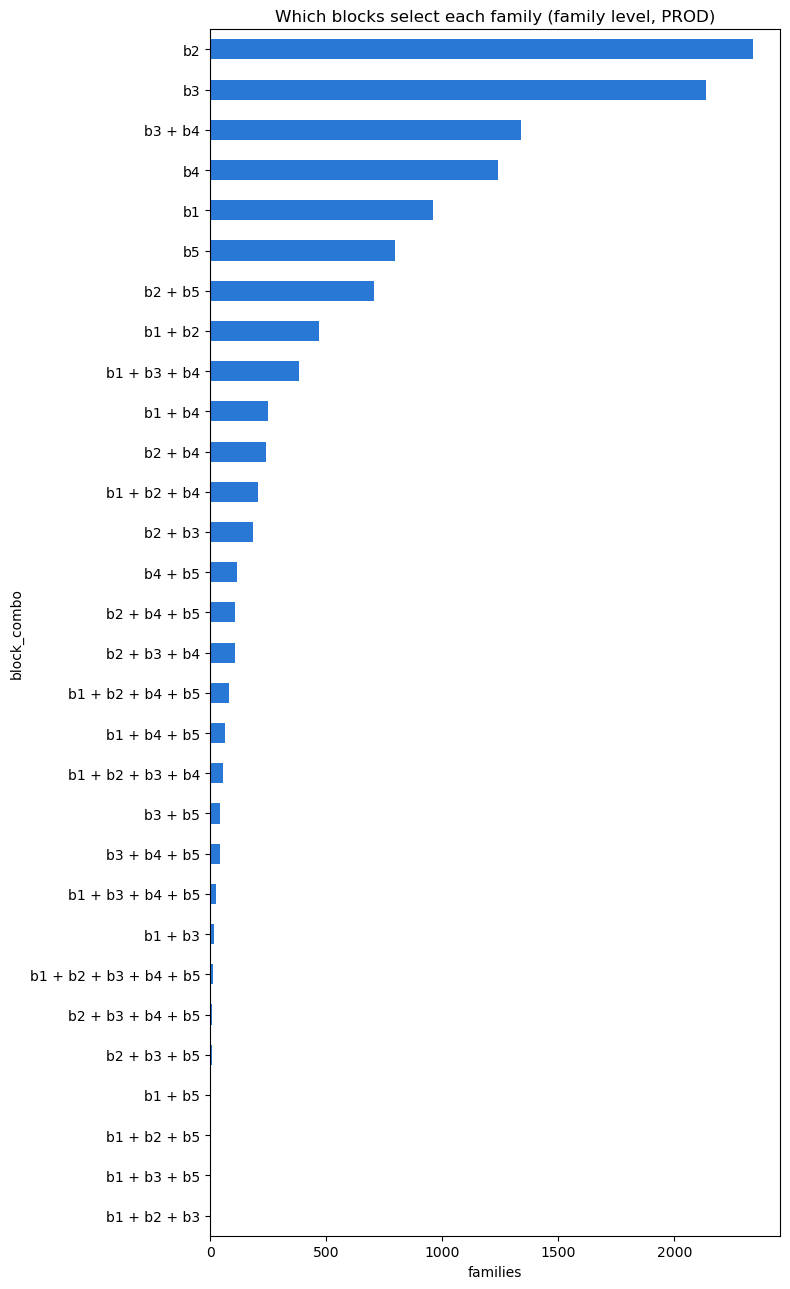

In [11]:
combo_counts = rule_sector["block_combo"].value_counts()
display(combo_counts.to_frame("families"))
alone = {b: int((rule_sector[b] & (rule_sector["n_blocks"] == 1)).sum()) for b in BLOCKS}
total = {b: int(rule_sector[b].sum()) for b in BLOCKS}
display(pd.DataFrame({"families with the block": total, "only this block": alone}))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(combo_counts) + 1))
combo_counts.sort_values().plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("families")
ax.set_title(f"Which blocks select each family ({C.MATCH_LEVEL} level, {C.ENV})")
plt.tight_layout()
fig.savefig(C.OUT_STEP0 / "block_overlap.png", dpi=150)
plt.show()

## 6 · Labelling protocol and samples

**Labelling protocol** (for the technical appendix):
1. **Definition** (`config.LABEL_DEFINITION`): an underwater drone is an unmanned vehicle that moves and works under
   water (ROVs, AUVs and UUVs, underwater gliders, robotic fish, seabed crawlers, hybrid vehicles that operate under
   water). The sector includes the drone itself, its parts (hull, propulsion, buoyancy, power, sensors, manipulators,
   tools carried or operated by it), its infrastructure (launch and recovery, docking, charging, tethers) and the
   methods to control, navigate and coordinate it.
2. **Rules.** Each family gets two labels. The **strict** rule defines the sector; the **broad** rule is kept only
   as a sensitivity check (an upper bound of precision), so the choice of rule is visible in the appendix.
   - `is_relevant` (**strict**) = 1 only if an underwater drone is the **subject** of the patent: the drone itself, a
     part or tool designed for one (the drone is named in the title or abstract), its infrastructure, or a method
     to control, navigate or coordinate it. 0 if no drone is involved, if one is only mentioned in passing ("without
     the need for divers or an ROV"), if an ROV only installs or operates generic subsea equipment (connectors,
     clamps, risers), or if the vehicle is not stated to be unmanned.
   - `is_relevant_broad` (**broad**) = 1 if the patent matches the definition **even partly**: also generic subsea
     equipment operated by an ROV, vehicles whose crew is not stated, submerged units of surface systems.
   - Always `is_relevant` ≤ `is_relevant_broad`. The reason goes in `note`.
3. **Grey zones** (write the zone in `grey_zone`, values in `config.GREY_ZONE_VALUES`):

   | Grey zone | `is_relevant` (strict) = 1 | strict = 0, broad = 1 | both 0 |
   |---|---|---|---|
   | offshore wind (`offshore_wind`) | a drone, its part or tool that inspects, maintains or installs wind farms | – | structures where an ROV is only mentioned |
   | surface–underwater (`hybrid_surface`) | an unmanned surface vessel that launches or recovers an underwater drone | submerged units of wave-driven or towed surface systems | surface drones alone |
   | air–water (`hybrid_air`) | a vehicle designed to fly and to move under water | multi-environment craft where water is one of many media | craft that only land on water |
   | crew not stated (`crew_not_stated`) | – (strict needs "unmanned", "autonomous", "remote", ROV/AUV/robot) | submersibles and vessels with no crew stated | crewed submarines, life support, passengers |
   | components (`generic_component`) | parts designed for a named underwater drone | parts for "submersibles" or "subsea equipment"; equipment installed by an ROV | generic marine parts (ship propellers, motors) |
   | outside the sea (`outside_sea`) | – | ROVs in nuclear pools or tanks | robots in dry environments |
   | other (`other`) | – | towed or tethered bodies, moored floating devices, test models | landers, floats, platforms without propulsion |

4. **How**: the labels are produced by applying the definition and the rule to each title and abstract, one family
   at a time, with the reason written in `note`; declare the method in the generative-AI statement.

**Samples written to `outputs/<env>/step0/`** (one row per family, **without** the flags that selected it, so
the labeller is not anchored; the flags are kept apart in `label_samples_key.csv`). Label them and save them in
`labels/` (e.g. `labels/sector_prod.csv`), with the `sample` column as written:

| File | Families | Used for |
|---|---|---|
| `label_sample_sector.csv` | `SAMPLE_SIZE` random sector families not labelled yet | precision (7.1) |
| `label_sample_broad_net.csv` | `BROAD_SAMPLE_SIZE` random families of the broad net outside the sector | recall (7.4) |
| `label_discovery.csv` (Section 8.2) | top families of BM25 and SBERT outside the sector | what text retrieval finds that the rules miss |

**Broad net.** A deliberately wide query (`config.BROAD_IPC`, `BROAD_CPC`, `BROAD_KEYWORDS`: IPC codes for
underwater vessels, sonar and acoustic communication, and generic phrases such as *underwater vehicle*). It catches
many non-relevant families, which is why it is not the sector; but the relevant families it finds outside the
sector are an estimate of what the sector misses.

In [12]:
b_cpc = real_pi(db.query(family_id).join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
                .filter(sql_prefix_any(TLS224_APPLN_CPC.cpc_class_symbol, C.BROAD_CPC)))
b_ipc = real_pi(db.query(family_id).join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
                .filter(sql_prefix_any(TLS209_APPLN_IPC.ipc_class_symbol, C.BROAD_IPC)))
b_title = real_pi(db.query(family_id).join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                  .filter(sql_like_any(TLS202_APPLN_TITLE.appln_title, C.BROAD_KEYWORDS)))
b_abs = real_pi(db.query(family_id).join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                .filter(sql_like_any(TLS203_APPLN_ABSTR.appln_abstract, C.BROAD_KEYWORDS)))
broad_ids = pd.DataFrame(patstat.df(b_cpc.union(b_ipc, b_title, b_abs)))["docdb_family_id"].astype("int64").unique()
broad_years = fetch_by_family(
    lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id,
                                 func.min(TLS201_APPLN.earliest_filing_year).label("family_year"))
                        .filter(TLS201_APPLN.docdb_family_id.in_(ids))
                        .filter(TLS201_APPLN.earliest_filing_year != C.MISSING_YEAR))
    .group_by(TLS201_APPLN.docdb_family_id),
    broad_ids,
)
broad_set = set(broad_years.loc[broad_years["family_year"].between(C.YEAR_MIN, C.YEAR_MAX), "docdb_family_id"])
rule_ids = set(rule_sector["docdb_family_id"])
broad_outside = broad_set - rule_ids
print(f"Broad net: {len(broad_set):,} families | in the sector: {len(broad_set & rule_ids):,} "
      f"| outside the sector: {len(broad_outside):,}")
print(f"Sector families the broad net does not find: {len(rule_ids - broad_set):,} "
      "(the blocks reach patents a generic query misses)")

Broad net: 34,866 families | in the sector: 10,275 | outside the sector: 24,591
Sector families the broad net does not find: 1,667 (the blocks reach patents a generic query misses)


In [13]:
LABEL_COLUMNS = ["docdb_family_id", "sample", "family_year", "first_office", "title_en", "abstract_en", "titles",
                 C.LABEL_COL, C.LABEL_COL_BROAD, "grey_zone", "note"]
KEY_COLUMNS = ["docdb_family_id", "block_combo", "in_sector_rules", "excluded"] + EXCLUSIONS + GZ
already = set(labels["docdb_family_id"])
keys = []


def to_label_file(df, name, sample, n=None):
    """Write a labelling file without block flags; keep the flags apart in the key file."""
    if df.empty:
        print(f"{name}: no family to label")
        return
    out = df.sample(n=min(n, len(df)), random_state=C.SEED) if n else df.copy()
    out["sample"] = sample
    for c in [C.LABEL_COL, C.LABEL_COL_BROAD, "grey_zone", "note"]:
        out[c] = ""
    out[[c for c in LABEL_COLUMNS if c in out.columns]].to_csv(C.OUT_STEP0 / name, index=False)
    keys.append(out[[c for c in KEY_COLUMNS if c in out.columns]].assign(file=name))
    print(f"{name}: {len(out)} families")


to_label_file(rule_sector[~rule_sector["docdb_family_id"].isin(already)], "label_sample_sector.csv", "sector",
              C.SAMPLE_SIZE)

pending = sorted(broad_outside - already)
if pending:
    sample_ids = pd.Series(pending).sample(n=min(C.BROAD_SAMPLE_SIZE, len(pending)), random_state=C.SEED).tolist()
    broad_fam = fam[fam["docdb_family_id"].isin(sample_ids)]
    missing = set(sample_ids) - set(broad_fam["docdb_family_id"])
    if missing:   # broad-net families outside the candidate pool: fetch their texts now
        t = fetch_by_family(lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
                                                .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                                                .filter(TLS201_APPLN.docdb_family_id.in_(ids))), missing)
        a = fetch_by_family(lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                                                .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                                                .filter(TLS201_APPLN.docdb_family_id.in_(ids))), missing)
        extra = pd.DataFrame({"docdb_family_id": sorted(missing)})
        if not t.empty:
            extra["title_en"] = extra["docdb_family_id"].map(t.drop_duplicates("docdb_family_id").set_index("docdb_family_id")["appln_title"])
        if not a.empty:
            extra["abstract_en"] = extra["docdb_family_id"].map(a.drop_duplicates("docdb_family_id").set_index("docdb_family_id")["appln_abstract"])
        extra = extra.merge(broad_years, on="docdb_family_id", how="left").assign(block_combo="outside candidate pool")
        broad_fam = pd.concat([broad_fam, extra], ignore_index=True)
    to_label_file(broad_fam, "label_sample_broad_net.csv", "broad_net_outside")
else:
    print("label_sample_broad_net.csv: no family to label")

if keys:
    pd.concat(keys, ignore_index=True).to_csv(C.OUT_STEP0 / "label_samples_key.csv", index=False)

label_sample_sector.csv: 100 families
label_sample_broad_net.csv: 50 families


## 7 · Validation

**What is validated is the sector given by the rules** (blocks minus exclusions), before the hand-labelled
corrections: the corrections use the same labels, so measuring the corrected sector on them would be circular.
Precision is measured on the labelled families of the rule sector (families labelled because the text methods
ranked them, `sample = discovery`, are left out: they are not a random sample). If they cover the whole rule
sector the share of relevant families is a **census**, not an estimate, and it is reported as such.
On PROD draw and label new samples: labels from TEST describe TEST families.

In [14]:
lab = rule_sector.merge(labels.drop(columns=[c for c in ["family_year", "first_office", "title_en", "abstract_en",
                                                         "titles"] if c in labels]),
                        on="docdb_family_id", how="inner")
lab = lab[lab["sample"] != "discovery"].copy()
if lab.empty:
    print("No labels for the sector yet: fill label_sample_sector.csv and save it in labels/.")
    P_SECTOR = P_SECTOR_BROAD = np.nan
else:
    k, n = int(lab[C.LABEL_COL].sum()), len(lab)
    lo, hi = wilson(k, n)
    kind = "census" if n == len(rule_sector) else f"sample of {n} out of {len(rule_sector)}"
    P_SECTOR = k / n
    print(f"7.1 Precision of the sector (strict rule): {k}/{n} = {P_SECTOR:.1%} (Wilson 95% CI {lo:.1%}-{hi:.1%}) [{kind}]")
    kb_, nb_ = int(lab[C.LABEL_COL_BROAD].sum()), len(lab)
    P_SECTOR_BROAD = kb_ / nb_
    print(f"    broad rule (upper bound): {kb_}/{nb_} = {P_SECTOR_BROAD:.1%} (Wilson 95% CI "
          f"{wilson(kb_, nb_)[0]:.1%}-{wilson(kb_, nb_)[1]:.1%}); the {kb_ - k} families in between are the grey zones "
          "the strict rule leaves out")

    print("\nPrecision by block combination")
    display(precision_table(lab, "block_combo"))
    print("Precision of each block (families that carry it, alone or with others)")
    display(pd.DataFrame({b: precision_table(lab[lab[b]], lambda _: b).iloc[0] for b in BLOCKS if lab[b].any()}).T)
    print("Precision by period (if it changes, growth rates in Step 1 are biased)")
    lab["period"] = pd.cut(lab["family_year"], bins=[1999, 2009, 2016, C.LAST_COMPLETE_YEAR, C.YEAR_MAX],
                           labels=["2000-09", "2010-16", f"2017-{C.LAST_COMPLETE_YEAR % 100}", "truncated"])
    display(precision_table(lab, "period"))
    print("Precision by first filing office (if it changes, geography in Step 1 is biased)")
    lab["office"] = lab["first_office"].where(lab["first_office"].isin(["CN", "US", "EP", "JP", "KR", "WO"]), "other")
    display(precision_table(lab, "office"))

7.1 Precision of the sector (strict rule): 220/253 = 87.0% (Wilson 95% CI 82.2%-90.6%) [sample of 253 out of 11942]
    broad rule (upper bound): 239/253 = 94.5% (Wilson 95% CI 90.9%-96.7%); the 19 families in between are the grey zones the strict rule leaves out

Precision by block combination


,n,relevant,precision,ci_low,ci_high
block_combo,,,,,
b1,34,22,0.647,0.479,0.785
b1 + b2,13,12,0.923,0.667,0.986
b1 + b2 + b3 + b4,4,3,0.750,0.301,0.954
b1 + b2 + b4,7,6,0.857,0.487,0.974
b1 + b2 + b4 + b5,3,3,1.000,0.438,1.000
b1 + b3 + b4,14,14,1.000,0.785,1.000
b1 + b4,9,9,1.000,0.701,1.000
b1 + b4 + b5,2,2,1.000,0.342,1.000
b2,40,34,0.850,0.709,0.929


Precision of each block (families that carry it, alone or with others)


,n,relevant,precision,ci_low,ci_high
b1_cpc,86.0,71.0,0.826,0.732,0.891
b2_specific,90.0,81.0,0.900,0.821,0.946
b3_generic,81.0,76.0,0.938,0.864,0.973
b4_neighbour,105.0,95.0,0.905,0.834,0.947
b5_acronym_title,42.0,41.0,0.976,0.877,0.996


Precision by period (if it changes, growth rates in Step 1 are biased)


,n,relevant,precision,ci_low,ci_high
period,,,,,
2000-09,11,8,0.727,0.434,0.903
2010-16,58,47,0.810,0.691,0.891
2017-22,149,136,0.913,0.856,0.948
truncated,35,29,0.829,0.673,0.919


Precision by first filing office (if it changes, geography in Step 1 is biased)


,n,relevant,precision,ci_low,ci_high
office,,,,,
CN,174,158,0.908,0.856,0.943
EP,4,4,1.000,0.510,1.000
JP,1,1,1.000,0.207,1.000
KR,7,5,0.714,0.359,0.918
US,34,28,0.824,0.665,0.917
WO,14,13,0.929,0.685,0.987
other,19,11,0.579,0.363,0.769


### 7.2 Agreement between labellers (optional)

If a second labeller fills `label_b` on some families (same definition and rule, without looking at
`is_relevant`), Cohen's kappa measures how reproducible the labels are.

In [15]:
from sklearn.metrics import cohen_kappa_score

d = lab[[C.LABEL_COL, "label_b"]].apply(pd.to_numeric, errors="coerce").dropna() if "label_b" in lab else pd.DataFrame()
if len(d) > 1 and d.nunique().min() > 1:
    print(f"Cohen's kappa is_relevant vs label_b: {cohen_kappa_score(d[C.LABEL_COL], d['label_b']):.2f} on {len(d)} families")
else:
    print("No second labelling (label_b): kappa not computed.")

No second labelling (label_b): kappa not computed.


### 7.3 Grey zones and exclusion rules

**Exclusion check.** The labelled families the exclusion rules removed should be (almost) all not relevant; the
precision of the sector with and without the exclusions shows what they gain.

**Grey-zone sensitivity.** Precision is recomputed (a) as labelled with the strict rule, (b) counting every
grey-zone family as relevant, (c) as not relevant, (d) leaving them out, (e) with the broad rule. If the four numbers lead to the same conclusion, the
grey-zone rule does not change the story of the deck; if they do not, say so in the appendix.

In [16]:
excl_lab = fam[fam["matched"] & fam["excluded"]].merge(labels[["docdb_family_id", C.LABEL_COL]], on="docdb_family_id")
matched_lab = fam[fam["matched"]].merge(labels[["docdb_family_id", C.LABEL_COL, "sample"]], on="docdb_family_id")
matched_lab = matched_lab[matched_lab["sample"] != "discovery"]
if not excl_lab.empty:
    ke, ne = int(excl_lab[C.LABEL_COL].sum()), len(excl_lab)
    print(f"Labelled families removed by the exclusion rules: {ne}, of which relevant: {ke}")
    rows = {}
    for name, d in {"blocks only": matched_lab, "blocks minus exclusions (the rule sector)":
                    matched_lab[~matched_lab["excluded"]]}.items():
        kk, nn = int(d[C.LABEL_COL].sum()), len(d)
        rows[name] = {"labelled": nn, "relevant": kk, "precision": kk / nn if nn else np.nan,
                      "ci_low": wilson(kk, nn)[0], "ci_high": wilson(kk, nn)[1]}
    display(pd.DataFrame(rows).T.round(3))

if not lab.empty:
    gz_lab = lab["grey_zone"].fillna("").astype(str).str.strip().ne("")
    source = "the labellers' grey_zone column"
    if not gz_lab.any():
        gz_lab, source = lab[GZ].any(axis=1), "the automatic topic flags (grey_zone is still empty)"
    sens = {}
    for name, y in {"(a) as labelled": lab[C.LABEL_COL],
                    "(b) grey zones = relevant": lab[C.LABEL_COL].where(~gz_lab, 1),
                    "(c) grey zones = not relevant": lab[C.LABEL_COL].where(~gz_lab, 0),
                    "(d) grey zones left out": lab.loc[~gz_lab, C.LABEL_COL],
                    "(e) broad rule (is_relevant_broad)": lab[C.LABEL_COL_BROAD]}.items():
        kk, nn = int(y.sum()), len(y)
        sens[name] = {"families": nn, "precision": kk / nn if nn else np.nan,
                      "ci_low": wilson(kk, nn)[0], "ci_high": wilson(kk, nn)[1]}
    print(f"\nGrey-zone sensitivity: {int(gz_lab.sum())} labelled sector families in a grey zone, from {source}")
    display(pd.DataFrame(sens).T.round(3))
    if lab["grey_zone"].fillna("").astype(str).str.strip().ne("").any():
        display(lab[gz_lab].groupby("grey_zone").agg(families=(C.LABEL_COL, "size"),
                                                     relevant_strict=(C.LABEL_COL, "sum"),
                                                     relevant_broad=(C.LABEL_COL_BROAD, "sum")))

Labelled families removed by the exclusion rules: 12, of which relevant: 0


,labelled,relevant,precision,ci_low,ci_high
blocks only,264.0,220.0,0.833,0.784,0.873
blocks minus exclusions (the rule sector),253.0,220.0,0.870,0.822,0.906



Grey-zone sensitivity: 57 labelled sector families in a grey zone, from the labellers' grey_zone column


,families,precision,ci_low,ci_high
(a) as labelled,253.0,0.870,0.822,0.906
(b) grey zones = relevant,253.0,0.968,0.939,0.984
(c) grey zones = not relevant,253.0,0.743,0.686,0.793
(d) grey zones left out,196.0,0.959,0.922,0.979
(e) broad rule (is_relevant_broad),253.0,0.945,0.909,0.967


,families,relevant_strict,relevant_broad
grey_zone,,,
crew_not_stated,4,1,4
generic_component,8,3,8
hybrid_air,15,8,10
hybrid_surface,12,8,12
offshore_wind,12,12,12
other,3,0,2
outside_sea,3,0,3


### 7.4 Recall relative to the broad net

Relevant families missed = share of relevant families in the labelled random sample of the broad net outside the
sector × number of those families. Recall = relevant in the sector / (relevant in the sector + relevant missed).
It is recall **relative to the broad net**: patents that neither query finds stay invisible; the text methods of
Section 8.2 look for them.

In [17]:
broad_lab = labels[labels["docdb_family_id"].isin(broad_outside) & labels["sample"].isin(["broad_net", "broad_net_outside"])]
if lab.empty or broad_lab.empty:
    print("Needs labels for the sector and for the broad-net sample (label_sample_broad_net.csv).")
    RECALL = np.nan
else:
    kb, nb = int(broad_lab[C.LABEL_COL].sum()), len(broad_lab)
    p_miss = kb / nb
    lo_b, hi_b = wilson(kb, nb)
    kept, missed = P_SECTOR * len(rule_sector), p_miss * len(broad_outside)
    RECALL = kept / (kept + missed)
    print(f"Broad-net families outside the sector: {len(broad_outside):,}; relevant among the {nb} labelled: {kb} "
          f"({p_miss:.1%}, Wilson {lo_b:.1%}-{hi_b:.1%})")
    print(f"Estimated relevant families: in the sector {kept:,.0f} | missed {missed:,.0f} "
          f"(range {lo_b * len(broad_outside):,.0f}-{hi_b * len(broad_outside):,.0f}) | recall {RECALL:.1%}")
    miss = broad_lab[broad_lab[C.LABEL_COL] == 1][["docdb_family_id"]].merge(
        fam[["docdb_family_id", "title_en", "block_combo"]], on="docdb_family_id", how="left")
    print("Relevant broad-net families the rules miss (they enter the sector through the corrections):")
    display(miss)

Broad-net families outside the sector: 24,591; relevant among the 132 labelled: 14 (10.6%, Wilson 6.4%-17.0%)
Estimated relevant families: in the sector 10,384 | missed 2,608 (range 1,580-4,185) | recall 79.9%
Relevant broad-net families the rules miss (they enter the sector through the corrections):


,docdb_family_id,title_en,block_combo
0,54435843,Underwater fish catching method based on image...,added by label
1,71760450,Water quality monitoring and early warning sys...,added by label
2,77864854,Emergency data security system for ocean surve...,added by label
3,84164123,"Underwater remote positioning system, method, ...",added by label
4,95422996,Underwater carrying device suitable for monito...,added by label
5,47530936,Underwater variant glider,added by label
6,92152723,Underwater vehicle control and three-dimension...,added by label
7,96564791,Underwater manta ray imitating robot,added by label
8,58173405,Underwater vehicle three-dimensional path plan...,added by label
9,40159533,Power unit of underwater vehicle,added by label


### 7.5 False positives worth reading

Sector families labelled **not** relevant, with the blocks that selected them: if most come from one block, that
block lets the noise in.

In [18]:
if not lab.empty:
    fp = lab[lab[C.LABEL_COL] == 0]
    print(f"{len(fp)} sector families labelled not relevant")
    display(fp[["docdb_family_id", "title_en", "block_combo"] + [c for c in ["grey_zone", "note"] if c in fp]])
    display(fp["block_combo"].value_counts().to_frame("false positives"))

33 sector families labelled not relevant


,docdb_family_id,title_en,block_combo,grey_zone,note
2,36337291,ROV FRIENDLY VORTEX INDUCED VIBRATION INHIBITOR,b5,generic_component,riser equipment designed to be installed by an...
13,47172667,ACTIVE GEOMETRIC EXOSKELETON WITH PSEUDO-RHOMB...,b4,hybrid_air,multi-environment craft or drone that also mov...
28,51788374,OIL SPILL RESPONSE SUBMARINE AND METHOD OF USE...,b1,crew_not_stated,oil-spill submarine with cameras; crew not stated
29,51934509,High speed surface craft and submersible vehicle,b1,crew_not_stated,surface craft and submersible vehicle; crew no...
32,52302299,SUBMERSIBLE VESSEL HAVING RETRACTABLE WING AND...,b1,crew_not_stated,submersible vessel; crew not stated
33,52628709,NODE DEPLOYER,b1,other,"towed, position-controlled underwater node dep..."
36,53758505,AUTONOMOUS POWER GENERATION IN SUBMERSIBLE ENV...,b1,,"borderline: generator enclosure, not a vehicle"
37,54544118,MOVING TOOLS ON OFFSHORE STRUCTURES WITH A WAL...,b1,other,robotic carriage walking along offshore struct...
40,55453143,ELECTRO-HYDRAULIC COMPACT DRIVE FOR ROTATIONAL...,b1,generic_component,"compact drive for underwater use (propeller, w..."
42,55926161,Deep ocean water pressure-retention sampling d...,b2,,water sampling device


,false positives
block_combo,
b1,12
b4,7
b2,6
b3,3
b5,1
b3 + b4,1
b1 + b2 + b4,1
b1 + b2,1
b1 + b2 + b3 + b4,1


### 7.6 Hand-labelled corrections

The final sector = rule sector − families labelled 0 + families labelled 1 that the rules miss (in the 2000–2025
window, patents of invention). On TEST almost every family is labelled, so the final sector is clean; on PROD only
the samples are labelled, and the rules (validated above) do most of the work.

In [19]:
corr = fam[fam["corr_removed"] | fam["corr_added"]].assign(
    correction=lambda d: np.where(d["corr_added"], "added (labelled 1)", "removed (labelled 0)"))
print(f"Rule sector {len(rule_sector):,} − {fam['corr_removed'].sum():,} + {fam['corr_added'].sum():,} "
      f"= final sector {len(sector):,} families")
if not corr.empty:
    display(corr[["docdb_family_id", "correction", "title_en"]].sort_values("correction"))
corr[["docdb_family_id", "correction"]].to_csv(C.OUT_STEP0 / "label_corrections.csv", index=False)

Rule sector 11,942 − 33 + 90 = final sector 11,999 families


,docdb_family_id,correction,title_en
789,34117148,added (labelled 1),UNMANNED OCEAN VEHICLE
16768,84104914,added (labelled 1),Method and apparatus for transporting ballast ...
16091,82573264,added (labelled 1),Deep sea autonomous environment monitoring pla...
15919,82233088,added (labelled 1),Underwater vehicle docking control method base...
15913,82219563,added (labelled 1),Non-destructive testing and cleaning apparatus
...,...,...,...
18867,88857372,removed (labelled 0),Hybrid power unmanned sailing boat driven by w...
8230,62745361,removed (labelled 0),DEEP-SEA MULTIFUNCTIONAL LONG-TERM IN-SITU OBS...
20048,91154971,removed (labelled 0),Marine surveying and mapping unmanned aerial v...
10101,67213708,removed (labelled 0),"Self-powered, self-propelled compute grid with..."


## 8 · Lexical vs semantic retrieval

Two experiments with the same methods, answering two different questions.

| | 8.1 Inside the sector | 8.2 Outside the sector |
|---|---|---|
| Families | labelled sector families | candidates the rules excluded, plus broad-net families outside the sector |
| Question | do the methods agree with the labels? | does any method find relevant families the query **misses**? |
| What it measures | precision and recall inside the sample | recall gain: relevant families that only text retrieval finds |

Inside an already clean sector almost every family is relevant, so all methods look good and differences are
not significant. Experiment 8.2 is the informative one.

**Methods**
- **A · keywords**: the keyword rules of blocks 2 and 3 on title + abstract.
- **BM25** (lexical, Tutorial 0): Okapi BM25 on abstract tokens (`pw_utils.BM25`). It saturates repeated terms
  and normalises by document length, so it is better suited than TF-IDF cosine to rank documents against a query.
- **TF-IDF** (lexical): cosine similarity of TF-IDF vectors (Tutorial 0, Notebook 1).
- **Patent SBERT** (`graziasveva93/sbert-adapt-ub`, semantic, Tutorial 0): cosine similarity of embeddings.

Each lexical or semantic method is used with two kinds of query: the **five focal patents** (score = highest
similarity to one of them) and a written **description** of the sector (as in Tutorial 0).

In [20]:
RUN_RETRIEVAL = True
RUN_SBERT = True
FOCAL_FAMILY_IDS = list(C.FOCAL_FAMILY_IDS)   # five typical sector patents, fetched by id (outside the evaluation pool)
SECTOR_DESCRIPTION = C.SECTOR_DESCRIPTION

# experiment 8.2
RUN_DISCOVERY = True
DISCOVERY_INCLUDE_BROAD = True     # add the broad-net families outside the sector (texts fetched now)
DISCOVERY_MAX_POOL = 20000         # random cap on the pool (SBERT on CPU: ~1-2 min per 1,000 abstracts on TIP)
DISCOVERY_TOP_K = 40               # families exported per method for labelling

In [21]:
from scipy.stats import binomtest
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from pw_utils import BM25, PATENT_STOP_WORDS, tokenize

_SBERT = {}


def sbert():
    """Load Patent SBERT once."""
    if "model" not in _SBERT:
        from sentence_transformers import SentenceTransformer
        _SBERT["model"] = SentenceTransformer(C.SBERT_MODEL)
    return _SBERT["model"]


def embed(texts):
    return sbert().encode(list(texts), batch_size=32, normalize_embeddings=True, show_progress_bar=True,
                          convert_to_numpy=True)


def mcnemar(truth, a, b):
    """Exact McNemar test on the correctness of two classifiers scored on the same items."""
    ca, cb = (a == truth), (b == truth)
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0


def top_k(scores, k):
    sel = np.zeros(len(scores), dtype=bool)
    sel[np.argsort(-scores, kind="stable")[:k]] = True
    return sel


def evaluate(name, sel, truth):
    tp = int((sel & truth).sum())
    p = tp / sel.sum() if sel.sum() else np.nan
    r = tp / truth.sum() if truth.sum() else np.nan
    lo, hi = wilson(tp, int(sel.sum()))
    return {"method": name, "selected": int(sel.sum()), "precision": p, "ci_low": lo, "ci_high": hi,
            "recall": r, "F1": 2 * p * r / (p + r) if p + r else np.nan}

### 8.1 Inside the sector (labelled sector families)

Every method selects the same number of families as A (k = keyword count), so precision and recall are compared
at equal size. All methods are scored **on the same families**, so methods are compared with McNemar's paired
test, not by looking at overlapping intervals. The focal families are excluded from the evaluation.

In [22]:
if RUN_RETRIEVAL and not lab.empty:
    # focal patents: fetched by family id, so they stay OUTSIDE the evaluation pool
    focal_df = fetch_by_family(
        lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                            .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                            .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
                            .filter(TLS201_APPLN.docdb_family_id.in_(ids))), FOCAL_FAMILY_IDS)
    focal_df = focal_df.drop_duplicates("docdb_family_id") if not focal_df.empty else focal_df
    print(f"{len(focal_df)} of {len(FOCAL_FAMILY_IDS)} focal patents found in {C.ENV}")

    ev = lab[lab["has_en_abstract"] & ~lab["docdb_family_id"].isin(FOCAL_FAMILY_IDS)].reset_index(drop=True)
    truth = ev[C.LABEL_COL].astype(bool).to_numpy()
    texts = ev["abstract_en"].fillna("").tolist()
    focal_texts = focal_df["appln_abstract"].fillna("").tolist() if len(focal_df) else []
    full = ((ev["title_en"].fillna("") + " " + ev["abstract_en"].fillna("")).str.lower())
    by_kw = (full.str.contains(RX_SPECIFIC) | full.str.contains(RX_GENERIC)).to_numpy()
    k = int(by_kw.sum())
    print(f"Evaluation set: {len(ev)} families, {truth.sum()} relevant | k = {k}")

    tokens = [tokenize(t) for t in texts]
    bm25 = BM25(tokens)
    s_bm25_desc = bm25.scores(tokenize(SECTOR_DESCRIPTION))
    sel = {"A · keywords": by_kw, "C · description BM25": top_k(s_bm25_desc, k)}
    if focal_texts:
        s_bm25_focal = np.max([bm25.scores(tokenize(t)) for t in focal_texts], axis=0)
        tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), ngram_range=(1, 2),
                                min_df=2, max_df=0.5, sublinear_tf=True).fit_transform(texts + focal_texts)
        s_tfidf = cosine_similarity(tfidf[:len(texts)], tfidf[len(texts):]).max(axis=1)
        sel["B · focal BM25"] = top_k(s_bm25_focal, k)
        sel["B · focal TF-IDF"] = top_k(s_tfidf, k)
    if RUN_SBERT:
        emb = embed(texts)
        desc_vec = embed([SECTOR_DESCRIPTION])[0]
        sel["C · description Patent SBERT"] = top_k(emb @ desc_vec, k)
        if focal_texts:
            emb_focal = embed(focal_texts)
            sel["B · focal Patent SBERT"] = top_k((emb @ emb_focal.T).max(axis=1), k)
            sel["A or B (SBERT)"] = sel["A · keywords"] | sel["B · focal Patent SBERT"]
            sel["A and B (SBERT)"] = sel["A · keywords"] & sel["B · focal Patent SBERT"]
    keep = np.ones(len(ev), dtype=bool)

    res = pd.DataFrame([evaluate(m, s, truth) for m, s in sel.items()]).set_index("method")
    res["McNemar p vs A"] = [np.nan if m == "A · keywords" else mcnemar(truth, sel["A · keywords"], sel[m])
                             for m in res.index]
    display(res.round(3))
    res.round(4).to_csv(C.OUT_STEP0 / "retrieval_evaluation.csv")

    if RUN_SBERT:   # the question of interest: lexical vs semantic with the same query
        pairs = {"focal: BM25 vs SBERT": ("B · focal BM25", "B · focal Patent SBERT"),
                 "description: BM25 vs SBERT": ("C · description BM25", "C · description Patent SBERT")}
        display(pd.Series({n: mcnemar(truth, sel[a], sel[b]) for n, (a, b) in pairs.items()
                           if a in sel and b in sel}, name="McNemar p", dtype=float).round(3).to_frame())
        sem_key = "B · focal Patent SBERT" if "B · focal Patent SBERT" in sel else "C · description Patent SBERT"
        only_sem = ev[sel[sem_key] & ~sel["A · keywords"]]
        print(f"\nFamilies found by SBERT and not by keywords ({len(only_sem)}): read them to look for missing terms")
        display(only_sem[["docdb_family_id", "title_en", C.LABEL_COL]])

5 of 5 focal patents found in PROD
Evaluation set: 245 families, 213 relevant | k = 159


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

,selected,precision,ci_low,ci_high,recall,F1,McNemar p vs A
method,,,,,,,
A · keywords,159,0.925,0.873,0.956,0.690,0.790,NaN
C · description BM25,159,0.874,0.814,0.917,0.653,0.747,0.141
B · focal BM25,159,0.874,0.814,0.917,0.653,0.747,0.125
B · focal TF-IDF,159,0.887,0.828,0.927,0.662,0.758,0.251
C · description Patent SBERT,159,0.906,0.850,0.942,0.676,0.774,0.572
B · focal Patent SBERT,159,0.881,0.821,0.922,0.657,0.753,0.165
A or B (SBERT),203,0.892,0.841,0.927,0.850,0.870,0.000
A and B (SBERT),115,0.922,0.858,0.958,0.498,0.646,0.000


,McNemar p
focal: BM25 vs SBERT,0.924
description: BM25 vs SBERT,0.302



Families found by SBERT and not by keywords (44): read them to look for missing terms


,docdb_family_id,title_en,is_relevant
2,36337291,ROV FRIENDLY VORTEX INDUCED VIBRATION INHIBITOR,0
4,40586839,SUBSEA OPERATIONS SUPPORT SYSTEM,1
5,40785422,CABLE CONNECTION SYSTEM FOR UNDERWATER VEHICLE,1
13,47172667,ACTIVE GEOMETRIC EXOSKELETON WITH PSEUDO-RHOMB...,0
19,49355836,Method and Apparatus to Facilitate Cleaning Ma...,1
20,49383796,AN UNDERWATER SELF-PROPELLED ROBOTIC SYSTEM,1
27,50570011,UUV three-dimension sea route planning method ...,1
31,52292737,UNDERWATER VEHICLE,1
33,52628709,NODE DEPLOYER,0
37,54544118,MOVING TOOLS ON OFFSHORE STRUCTURES WITH A WAL...,0


### 8.2 Outside the sector: does text retrieval find what the rules miss?

**Pool**: candidate families outside the rule sector (they carry a sector CPC code or a keyword phrase, but fail
the rules), plus, if `DISCOVERY_INCLUDE_BROAD`, the broad-net families outside the sector. Only families with an
English abstract can be ranked.

**Rankings** (no labels needed):
- **BM25 · description**: lexical match with the sector description;
- **SBERT · description**: semantic similarity to the same description;
- **SBERT · sector centroid**: similarity to the average embedding of the sector families, i.e. "looks like the
  patents already in the sector".

The top `DISCOVERY_TOP_K` of each ranking go to `label_discovery.csv` (union, with each method's rank).
Label `is_relevant` (strict) and `is_relevant_broad` with the rules of Section 6, keep `sample = discovery` and save the file in `labels/`.

**How to read the result** (after labelling, next cell):
- *precision@k* of each ranking = share of relevant families among its top k. These families are all **missed by
  the rules**, so a high precision@k means the rules have a recall problem, and tells which method finds them.
- The number of relevant families found is a **lower bound** of what the query misses (only the top of each
  ranking is read). It is not a random sample, so it is not extrapolated to the pool.
- The word pairs most frequent in the relevant families found suggest **new keywords**.
- The relevant families found enter the sector through the corrections (4, 7.6).

In [23]:
discovery = pd.DataFrame()
if RUN_DISCOVERY:
    pool = fam.loc[~fam["in_sector_rules"] & fam["has_en_abstract"],
                   ["docdb_family_id", "family_year", "first_office", "title_en", "abstract_en", "block_combo"]]
    pool = pool.assign(source="excluded candidate")
    if DISCOVERY_INCLUDE_BROAD:
        extra_ids = sorted(broad_outside - set(fam["docdb_family_id"]))
        if extra_ids:
            ab = fetch_by_family(lambda ids: db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                                 .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                                 .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
                                 .filter(TLS201_APPLN.docdb_family_id.in_(ids)), extra_ids)
            ti = fetch_by_family(lambda ids: db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
                                 .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                                 .filter(TLS202_APPLN_TITLE.appln_title_lg == "en")
                                 .filter(TLS201_APPLN.docdb_family_id.in_(ids)), extra_ids)
            if not ab.empty:
                broad_pool = (ab.drop_duplicates("docdb_family_id").rename(columns={"appln_abstract": "abstract_en"})
                             .merge(ti.drop_duplicates("docdb_family_id").rename(columns={"appln_title": "title_en"})
                                    if not ti.empty else pd.DataFrame(columns=["docdb_family_id", "title_en"]),
                                    on="docdb_family_id", how="left")
                             .merge(broad_years, on="docdb_family_id", how="left")
                             .assign(source="broad net only (outside candidate pool)", block_combo="-"))
                pool = pd.concat([pool, broad_pool], ignore_index=True)
        pool.loc[pool["docdb_family_id"].isin(broad_outside) & pool["source"].eq("excluded candidate"),
                 "source"] = "excluded candidate, in the broad net"
    pool = pool.drop_duplicates("docdb_family_id").reset_index(drop=True)
    if len(pool) > DISCOVERY_MAX_POOL:
        pool = pool.sample(DISCOVERY_MAX_POOL, random_state=C.SEED).reset_index(drop=True)
    print(f"Discovery pool: {len(pool):,} families with an English abstract")
    display(pool["source"].value_counts().to_frame("families"))

    texts_pool = pool["abstract_en"].fillna("").tolist()
    ranks = {"BM25 · description": BM25([tokenize(t) for t in texts_pool]).scores(tokenize(SECTOR_DESCRIPTION))}
    if RUN_SBERT:
        emb_pool = embed(texts_pool)
        desc_vec = embed([SECTOR_DESCRIPTION])[0]
        ranks["SBERT · description"] = emb_pool @ desc_vec
        sector_en = rule_sector[rule_sector["has_en_abstract"]].reset_index(drop=True)   # kept for the UMAP maps (8.3)
        emb_sector = embed(sector_en["abstract_en"].fillna(""))
        centroid = emb_sector.mean(axis=0)
        ranks["SBERT · sector centroid"] = emb_pool @ (centroid / np.linalg.norm(centroid))

    for name, score in ranks.items():
        pool[f"score {name}"] = score
        pool[f"rank {name}"] = pd.Series(score).rank(ascending=False, method="first").astype(int).values
    rank_cols = [c for c in pool.columns if c.startswith("rank ")]
    in_top = (pool[rank_cols] <= DISCOVERY_TOP_K)
    discovery = pool[in_top.any(axis=1)].copy()
    discovery["found_by"] = in_top[in_top.any(axis=1)].apply(
        lambda r: " + ".join(c.replace("rank ", "") for c in rank_cols if r[c]), axis=1)
    discovery["best_rank"] = discovery[rank_cols].min(axis=1)
    discovery = discovery.sort_values("best_rank")

    known = (labels.drop_duplicates("docdb_family_id", keep="last").set_index("docdb_family_id")
             if not labels.empty else pd.DataFrame(columns=[C.LABEL_COL, C.LABEL_COL_BROAD]))
    for c in [C.LABEL_COL, C.LABEL_COL_BROAD]:   # pre-filled only if already labelled
        discovery[c] = discovery["docdb_family_id"].map(known[c]) if c in known else np.nan
    discovery["note"] = ""
    discovery["grey_zone"] = ""
    # the labelling file hides which method found each family (no anchoring); the ranks go to a separate key file
    discovery["sample"] = "discovery"
    label_cols = ["docdb_family_id", "sample", "family_year", "title_en", "abstract_en", C.LABEL_COL, C.LABEL_COL_BROAD,
                  "grey_zone", "note"]
    discovery[label_cols].sample(frac=1, random_state=C.SEED).to_csv(C.OUT_STEP0 / "label_discovery.csv", index=False)
    discovery[["docdb_family_id", "source", "block_combo", "found_by", "best_rank"] + rank_cols].to_csv(
        C.OUT_STEP0 / "discovery_ranks.csv", index=False)
    print(f"label_discovery.csv: {len(discovery)} families (union of the top {DISCOVERY_TOP_K} of each ranking)")
    display(discovery["found_by"].value_counts().to_frame("families"))

Discovery pool: 20,000 families with an English abstract


,families
source,
broad net only (outside candidate pool),12089
excluded candidate,4803
"excluded candidate, in the broad net",3108


Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/370 [00:00<?, ?it/s]

label_discovery.csv: 115 families (union of the top 40 of each ranking)


,families
found_by,
BM25 · description,38
SBERT · description,36
SBERT · sector centroid,36
SBERT · description + SBERT · sector centroid,3
BM25 · description + SBERT · sector centroid,1
BM25 · description + SBERT · description,1


In [24]:
disc_lab = labels[labels["docdb_family_id"].isin(discovery["docdb_family_id"])] if not discovery.empty else labels.iloc[0:0]
if discovery.empty or disc_lab.empty:
    print("Label label_discovery.csv and save it in labels/ (sample = discovery), then re-run.")
else:
    d = discovery.drop(columns=[C.LABEL_COL]).merge(disc_lab[["docdb_family_id", C.LABEL_COL]], on="docdb_family_id")
    rows = []
    for name in ranks:
        for kk in (10, 20, DISCOVERY_TOP_K):
            top = d[d[f"rank {name}"] <= kk]
            rel, n = int(top[C.LABEL_COL].sum()), len(top)
            lo, hi = wilson(rel, n)
            rows.append({"ranking": name, "k": kk, "labelled": n, "relevant": rel,
                         "precision@k": rel / n if n else np.nan, "ci_low": lo, "ci_high": hi})
    p_at_k = pd.DataFrame(rows).set_index(["ranking", "k"]).round(3)
    display(p_at_k)
    p_at_k.to_csv(C.OUT_STEP0 / "discovery_precision_at_k.csv")

    relevant = d[d[C.LABEL_COL] == 1]
    print(f"Relevant families missed by the rules and found by text retrieval: {len(relevant)} "
          f"(a lower bound) | by source:")
    display(relevant["source"].value_counts().to_frame("relevant"))
    print("Relevant families, by the ranking(s) that found them (one name = found by that method only):")
    display(relevant["found_by"].value_counts().to_frame("relevant"))

    # candidate new keywords: word pairs over-represented in the relevant families found
    if len(relevant) >= 3 and len(d) > len(relevant):
        cv = CountVectorizer(ngram_range=(2, 2), stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), min_df=2)
        X = cv.fit_transform((d["title_en"].fillna("") + " " + d["abstract_en"].fillna("")).tolist())
        is_rel = (d[C.LABEL_COL] == 1).to_numpy()
        f_rel = np.asarray(X[is_rel].sum(axis=0)).ravel() + 0.5
        f_non = np.asarray(X[~is_rel].sum(axis=0)).ravel() + 0.5
        log_odds = np.log(f_rel / f_rel.sum()) - np.log(f_non / f_non.sum())
        terms = pd.DataFrame({"bigram": cv.get_feature_names_out(), "in relevant": f_rel - 0.5,
                              "in non-relevant": f_non - 0.5, "log-odds": log_odds})
        display(terms[terms["in relevant"] >= 2].sort_values("log-odds", ascending=False).head(20).round(2))

labelled  relevant  precision@k  ci_low  ci_high
ranking                 k                                                   
BM25 · description      10         7         2        0.286   0.082    0.641
                        20        14         6        0.429   0.214    0.674
                        40        28        13        0.464   0.295    0.642
SBERT · description     10         6         4        0.667   0.300    0.903
                        20        12         7        0.583   0.320    0.807
                        40        23        13        0.565   0.368    0.744
SBERT · sector centroid 10         6         4        0.667   0.300    0.903
                        20        13         8        0.615   0.355    0.823
                        40        22        15        0.682   0.473    0.836

Relevant families missed by the rules and found by text retrieval: 39 (a lower bound) | by source:


,relevant
source,
"excluded candidate, in the broad net",38
excluded candidate,1


Relevant families, by the ranking(s) that found them (one name = found by that method only):


,relevant
found_by,
SBERT · sector centroid,13
BM25 · description,12
SBERT · description,12
BM25 · description + SBERT · sector centroid,1
SBERT · description + SBERT · sector centroid,1


,bigram,in relevant,in non-relevant,log-odds
181,robot underwater,13.0,0.0,2.70
22,body unmanned,11.0,0.0,2.54
202,target position,10.0,0.0,2.45
50,control underwater,10.0,0.0,2.45
230,unmanned vehicle,10.0,0.0,2.45
220,underwater operation,6.0,0.0,1.97
128,navigation positioning,5.0,0.0,1.80
151,positioning information,5.0,0.0,1.80
190,self supply,5.0,0.0,1.80
218,underwater integrated,5.0,0.0,1.80


### 8.3 UMAP maps of the semantic space

As in Tutorial 0 (section 6.7), the Patent SBERT embeddings are projected to two dimensions with UMAP
(cosine metric, `n_neighbors = 15`, `min_dist = 0.1`, fixed seed), **together with** the sector description,
drawn as a star. Three maps, saved in `outputs/<env>/step0/` for the technical appendix:

1. **Sector vs excluded families**: if excluded families sit inside the sector's cloud, the query is missing
   something there; if they form separate regions, the query separates well. After labelling `label_discovery.csv`,
   the relevant families found outside the sector are circled: they show *where* the query has gaps.
2. **BM25 vs SBERT**: the top `DISCOVERY_TOP_K` of each method on the same map. BM25 tends to stay close to the
   words of the description, SBERT to reach semantically close regions with different wording.
3. **The sector by block**: where the families selected by each block (or combination) lie; families selected by
   the CPC block alone at the margins would match its lower precision.

**How to read UMAP**: it preserves neighbourhoods, not distances. Clusters and overlaps are qualitative evidence;
do not read sizes of clusters or gaps between them as measures. Colour and marker shape both encode the group.

In [25]:
RUN_UMAP = True
UMAP_MAX_POINTS = 30000   # random cap for speed (UMAP on 4 CPU cores: about a minute for 20,000 points)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # validated categorical order
MARKERS = ["o", "s", "^", "D", "v", "P"]
INK, MUTED = "#0b0b0b", "#a3a29c"


def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#d9d8d4")
    ax.set_xlabel("UMAP 1", color="#52514e"); ax.set_ylabel("UMAP 2", color="#52514e")


def draw_description(ax, xy):
    ax.scatter(*xy, marker="*", s=380, color=INK, edgecolor="white", linewidth=1.2, zorder=5,
               label="sector description")


umap_ok = RUN_UMAP and RUN_DISCOVERY and RUN_SBERT and "emb_pool" in globals()
if umap_ok:
    try:
        import umap
    except ImportError:
        print("umap-learn is not installed: run  %pip install -q umap-learn  and re-run this cell")
        umap_ok = False

if umap_ok:
    pts = pd.concat([
        sector_en[["docdb_family_id", "block_combo"]].assign(group="sector"),
        pool[["docdb_family_id", "block_combo", "source"]].rename(columns={"source": "group"}),
    ], ignore_index=True)
    E = np.vstack([emb_sector, emb_pool])
    if len(pts) > UMAP_MAX_POINTS:
        keep_idx = pts.sample(UMAP_MAX_POINTS, random_state=C.SEED).index.to_numpy()
        pts, E = pts.loc[keep_idx].reset_index(drop=True), E[keep_idx]
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=C.SEED)
    coords = reducer.fit_transform(np.vstack([E, desc_vec.reshape(1, -1)]))
    pts[["UMAP_1", "UMAP_2"]] = coords[:-1]
    desc_xy = coords[-1]
    for name in ranks:   # attach the ranks of 8.2 to the excluded families
        pts = pts.merge(pool[["docdb_family_id", f"rank {name}"]], on="docdb_family_id", how="left")
    if not disc_lab.empty:
        pts = pts.merge(disc_lab[["docdb_family_id", C.LABEL_COL]].rename(columns={C.LABEL_COL: "disc_label"}),
                        on="docdb_family_id", how="left")
    print(f"UMAP on {len(pts):,} families")
    display(pts["group"].value_counts().to_frame("points"))

/home/s353699/.local/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP on 30,000 families


,points
group,
broad net only (outside candidate pool),11429
sector,11127
excluded candidate,4522
"excluded candidate, in the broad net",2922


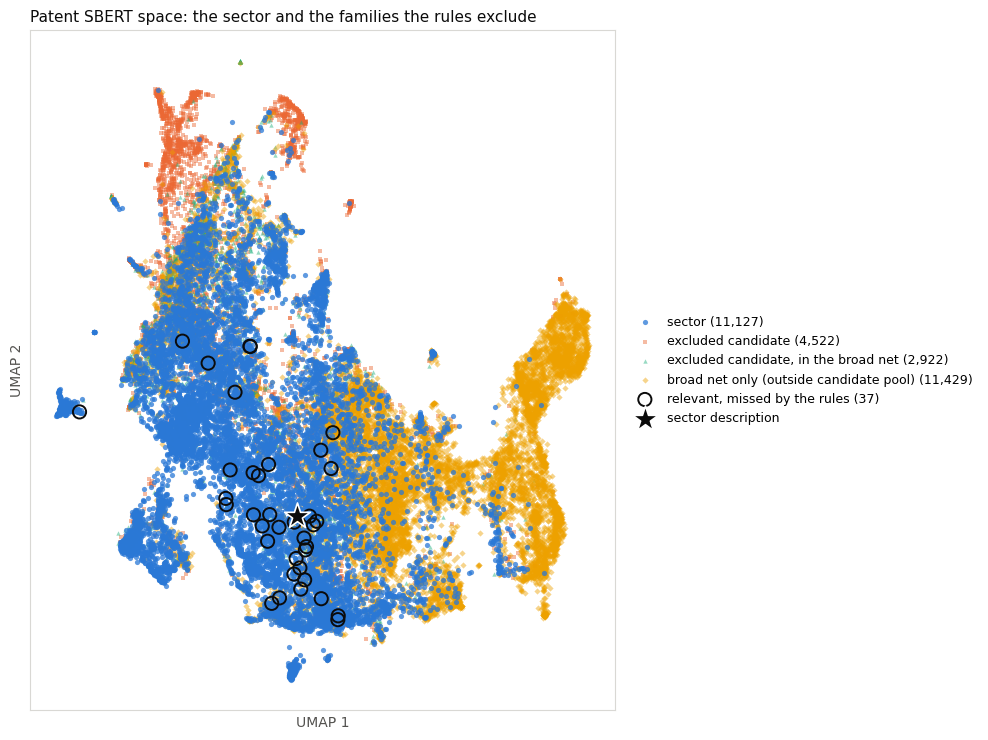

In [26]:
if umap_ok:   # Map 1: sector vs excluded families
    groups = ["sector", "excluded candidate", "excluded candidate, in the broad net", "broad net only (outside candidate pool)"]
    fig, ax = plt.subplots(figsize=(10, 7.5))
    for i, g in enumerate([g for g in groups if g in set(pts["group"])]):
        d = pts[pts["group"] == g]
        ax.scatter(d["UMAP_1"], d["UMAP_2"], s=10 if i else 14, alpha=0.75 if i == 0 else 0.45,
                   color=COLORS[i], marker=MARKERS[i], linewidths=0, label=f"{g} ({len(d):,})", zorder=2 if i == 0 else 1)
    if "disc_label" in pts:
        rel = pts[pts["disc_label"] == 1]
        ax.scatter(rel["UMAP_1"], rel["UMAP_2"], s=90, facecolors="none", edgecolors=INK, linewidths=1.4, zorder=4,
                   label=f"relevant, missed by the rules ({len(rel)})")
    draw_description(ax, desc_xy)
    style(ax, "Patent SBERT space: the sector and the families the rules exclude")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_sector_vs_excluded.png", dpi=200, bbox_inches="tight")
    plt.show()

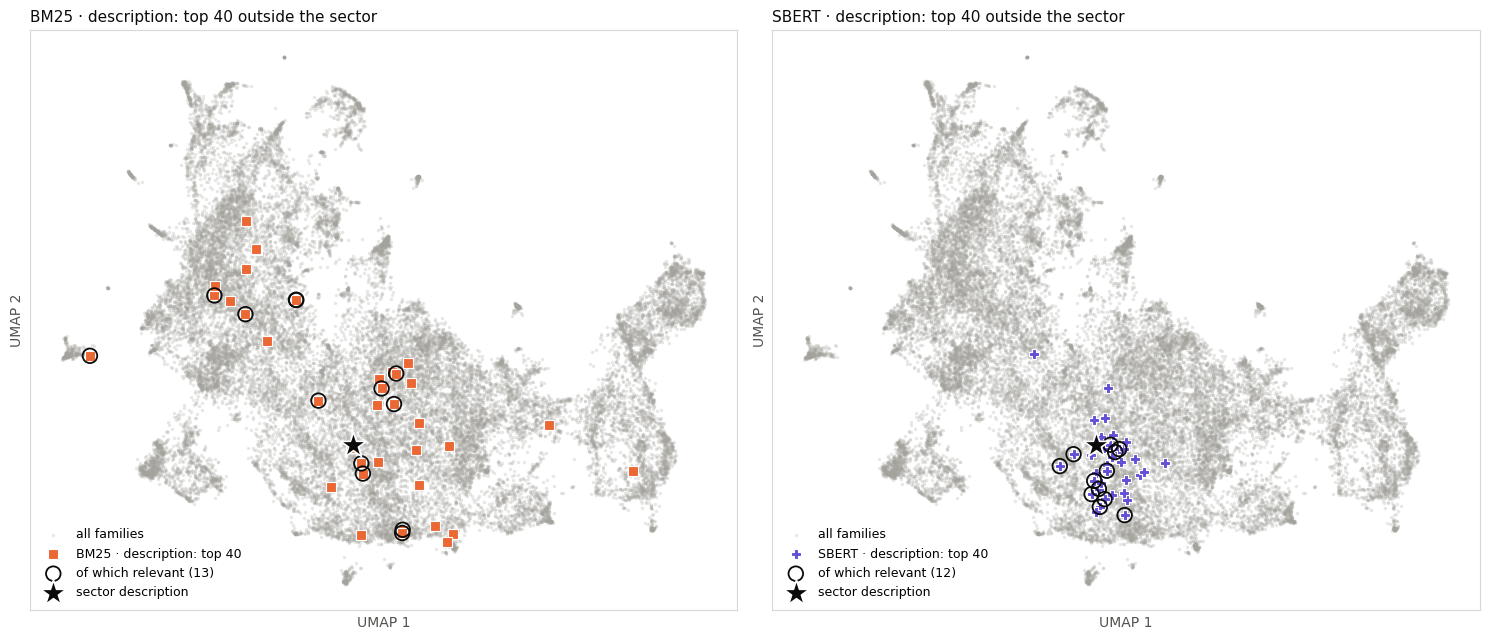

Families in both top-40 lists: 1 (2%)


In [27]:
if umap_ok:   # Map 2: BM25 vs SBERT top-K, same query (sector description)
    pairs_map = [("BM25 · description", COLORS[1], MARKERS[1]), ("SBERT · description", COLORS[5], MARKERS[5])]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
    for ax, (name, color, marker) in zip(axes, pairs_map):
        ax.scatter(pts["UMAP_1"], pts["UMAP_2"], s=6, color=MUTED, alpha=0.25, linewidths=0, label="all families")
        top = pts[pts[f"rank {name}"] <= DISCOVERY_TOP_K]
        ax.scatter(top["UMAP_1"], top["UMAP_2"], s=42, color=color, marker=marker, edgecolor="white",
                   linewidth=0.8, zorder=3, label=f"{name}: top {DISCOVERY_TOP_K}")
        if "disc_label" in pts:
            rel = top[top["disc_label"] == 1]
            ax.scatter(rel["UMAP_1"], rel["UMAP_2"], s=110, facecolors="none", edgecolors=INK, linewidths=1.3,
                       zorder=4, label=f"of which relevant ({len(rel)})")
        draw_description(ax, desc_xy)
        style(ax, f"{name}: top {DISCOVERY_TOP_K} outside the sector")
        ax.legend(loc="lower left", frameon=False, fontsize=9)
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_bm25_vs_sbert.png", dpi=200, bbox_inches="tight")
    plt.show()
    both = ((pts["rank BM25 · description"] <= DISCOVERY_TOP_K) &
            (pts["rank SBERT · description"] <= DISCOVERY_TOP_K)).sum()
    print(f"Families in both top-{DISCOVERY_TOP_K} lists: {both} ({both / DISCOVERY_TOP_K:.0%})")

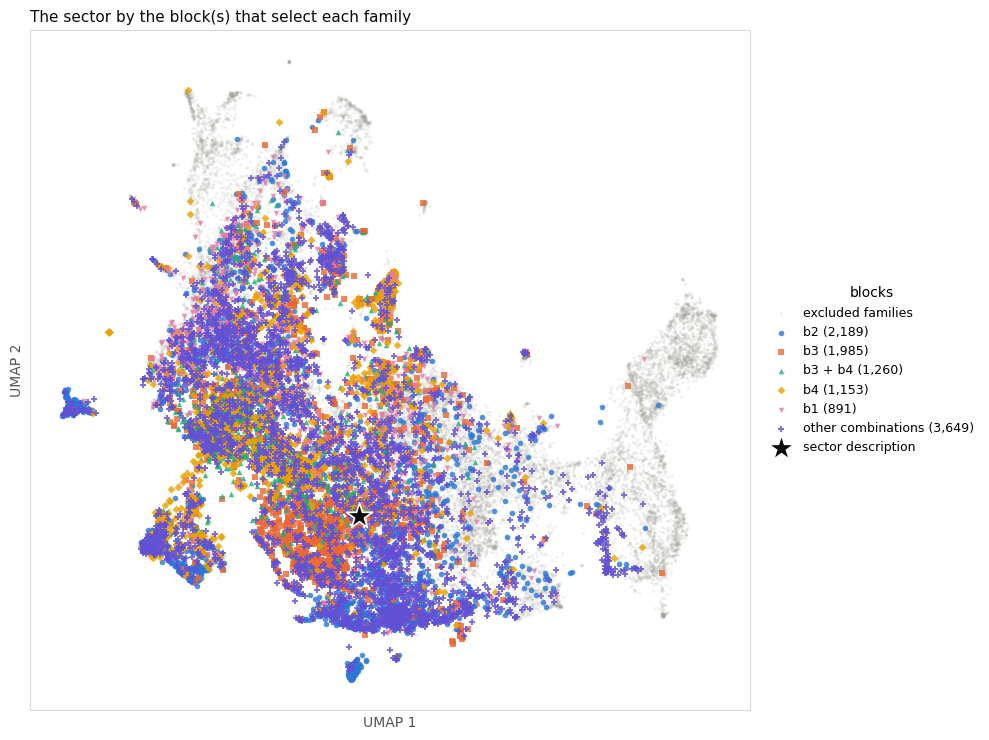

In [28]:
if umap_ok:   # Map 3: the sector by block combination
    sec = pts[pts["group"] == "sector"].copy()
    top_combos = sec["block_combo"].value_counts().index[:5].tolist()   # fixed order: largest first
    sec["combo"] = sec["block_combo"].where(sec["block_combo"].isin(top_combos), "other combinations")
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(pts["UMAP_1"], pts["UMAP_2"], s=5, color=MUTED, alpha=0.15, linewidths=0, label="excluded families")
    for i, c in enumerate(top_combos + (["other combinations"] if (sec["combo"] == "other combinations").any() else [])):
        d = sec[sec["combo"] == c]
        ax.scatter(d["UMAP_1"], d["UMAP_2"], s=16, color=COLORS[i % len(COLORS)], marker=MARKERS[i % len(MARKERS)],
                   alpha=0.8, linewidths=0, label=f"{c} ({len(d):,})")
    draw_description(ax, desc_xy)
    style(ax, "The sector by the block(s) that select each family")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9, title="blocks")
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_sector_blocks.png", dpi=200, bbox_inches="tight")
    plt.show()

## 9 · Outputs

| File | Content |
|---|---|
| `sector_families.csv` | one row per sector family (final sector): family year, truncation flag, first office, block and exclusion flags, corrections |
| `candidates_all.csv` | all candidate families with their flags (to reproduce the block analysis) |
| `raw/*.csv.gz` | applications, titles, abstracts, CPC and IPC of the sector families, reused by `02_clean` |
| `block_overlap.png`, `retrieval_evaluation.csv`, `umap_*.png` | figures and tables for the technical appendix |
| `label_sample_sector.csv`, `label_sample_broad_net.csv`, `label_discovery.csv` | files to label (no flags) |
| `label_samples_key.csv`, `discovery_ranks.csv` | flags and method ranks of the families to label (not for labellers) |
| `label_corrections.csv` | families removed or added by the hand-labelled corrections |
| `discovery_precision_at_k.csv`, `step0_summary.csv` | precision@k of BM25 and SBERT outside the sector; the key numbers of Section 10 |

In [29]:
FLAG_COLS = (["docdb_family_id", "family_year", "is_truncated", "first_office", "has_en_abstract"] + FLAGS
             + ["matched", "excluded", "in_sector_application", "in_sector_family", "in_sector_rules",
                "corr_removed", "corr_added", "n_blocks", "block_combo", "in_sector"] + GZ)
sector[FLAG_COLS].to_csv(C.OUT_STEP0 / "sector_families.csv", index=False)
fam[FLAG_COLS].to_csv(C.OUT_STEP0 / "candidates_all.csv", index=False)

ids = set(sector["docdb_family_id"])
apps[apps["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "applications.csv.gz", index=False)
titles[titles["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "titles.csv.gz", index=False)
abstracts[abstracts["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "abstracts.csv.gz", index=False)
cpc[cpc["docdb_family_id"].isin(ids)][["docdb_family_id", "appln_id", "cpc"]].to_csv(
    C.OUT_STEP0 / "raw" / "cpc.csv.gz", index=False)
if not ipc.empty:
    ipc[ipc["docdb_family_id"].isin(ids)][["docdb_family_id", "appln_id", "ipc"]].to_csv(
        C.OUT_STEP0 / "raw" / "ipc.csv.gz", index=False)

print(f"Saved in {C.OUT_STEP0.resolve()}: {len(sector):,} sector families")

Saved in /home/jovyan/Team10/v3/outputs/prod/step0: 11,999 sector families


## 10 · Summary

The key numbers of Step 0 in one table (saved as `step0_summary.csv`), with the checks that are still open.
Only the PROD numbers go in the deck.

In [30]:
def pct(k, n):
    lo, hi = wilson(k, n)
    return f"{k / n:.0%} ({lo:.0%}-{hi:.0%}, {k}/{n})" if n else "n/a"


summary = {"environment": C.ENV, "IPR type": C.IPR_TYPE, "matching level": C.MATCH_LEVEL,
           "families selected by the blocks": int(fam["matched"].sum()),
           "removed by the grey-zone exclusion rules": int((fam["matched"] & fam["excluded"]).sum()),
           "sector given by the rules": len(rule_sector),
           "hand-labelled corrections (removed / added)": f"{int(fam['corr_removed'].sum())} / {int(fam['corr_added'].sum())}",
           "FINAL SECTOR (families)": len(sector),
           "of which truncated": int(sector["is_truncated"].sum())}
if not lab.empty:
    summary["precision of the rule sector (strict rule)"] = pct(int(lab[C.LABEL_COL].sum()), len(lab))
    summary["precision of the rule sector (broad rule, upper bound)"] = pct(int(lab[C.LABEL_COL_BROAD].sum()), len(lab))
if not np.isnan(RECALL):
    summary["recall relative to the broad net"] = f"{RECALL:.0%}"
checks = {
    "labels found in labels/": not labels.empty,
    "broad-net sample labelled": not broad_lab.empty,
    "discovery sample labelled": not disc_lab.empty,
    "grey_zone column filled": labels["grey_zone"].ne("").any() if not labels.empty else False,
    "run on PROD": C.ENV == "PROD",
}
summary.update({f"check: {k}": ("yes" if v else "NO") for k, v in checks.items()})
summary_df = pd.Series(summary, name="value").to_frame()
display(summary_df)
summary_df.to_csv(C.OUT_STEP0 / "step0_summary.csv")
if not all(checks.values()):
    print("Provisional: " + ", ".join(k for k, v in checks.items() if not v) + ".")

,value
environment,PROD
IPR type,PI
matching level,family
families selected by the blocks,12046
removed by the grey-zone exclusion rules,104
sector given by the rules,11942
hand-labelled corrections (removed / added),33 / 90
FINAL SECTOR (families),11999
of which truncated,4198
precision of the rule sector (strict rule),"87% (82%-91%, 220/253)"
